In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
URL = 'https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv'

In [8]:
births = pd.read_csv(URL)

# First five rows
display(births.head())

# Shape and column dtypes
print('Shape :', births.shape)
print('\nColumn dtypes:')
print(births.dtypes)

,year,month,day,gender,births
0,1969,1,1.0,F,4046
1,1969,1,1.0,M,4440
2,1969,1,2.0,F,4454
3,1969,1,2.0,M,4548
4,1969,1,3.0,F,4548


Shape : (15547, 5)

Column dtypes:
year        int64
month       int64
day       float64
gender        str
births      int64
dtype: object


In [9]:
# Why is `day` not an integer? Look at the missing values and odd placeholder values.
print('Missing values per column:')
print(births.isna().sum())
print('\nMost unusual day values:')
print(births['day'].value_counts().sort_index().tail(6))

Missing values per column:
year        0
month       0
day       480
gender      0
births      0
dtype: int64

Most unusual day values:
day
27.0    480
28.0    480
29.0    464
30.0    450
31.0    363
99.0    350
Name: count, dtype: int64


In [10]:
# Add a decade column: 1969 -> 1960, 1975 -> 1970, ...
births['decade'] = 10 * (births['year'] // 10)

# Total births with decade as rows and gender as columns
decade_gender = births.pivot_table('births', index='decade', columns='gender', aggfunc='sum')
display(decade_gender)

gender,F,M
decade,,
1960,1753634,1846572
1970,16263075,17121550
1980,18310351,19243452
1990,19479454,20420553
2000,18229309,19106428


In [12]:
print('Males > females in every decade?', bool((decade_gender['M'] > decade_gender['F']).all()))
display((decade_gender['M'] > decade_gender['F']).rename('M > F'))

Males > females in every decade? True


decade
1960    True
1970    True
1980    True
1990    True
2000    True
Name: M > F, dtype: bool

In [13]:
summary = pd.DataFrame({
    'M/F ratio': decade_gender['M'] / decade_gender['F'],
    'Male excess (%)': (decade_gender['M'] / decade_gender['F'] - 1) * 100,
})
display(summary.round(4))
print('Overall M/F ratio       :', round(decade_gender['M'].sum() / decade_gender['F'].sum(), 4))

,M/F ratio,Male excess (%)
decade,,
1960,1.0530,5.2997
1970,1.0528,5.2787
1980,1.0510,5.0960
1990,1.0483,4.8312
2000,1.0481,4.8116


Overall M/F ratio       : 1.05


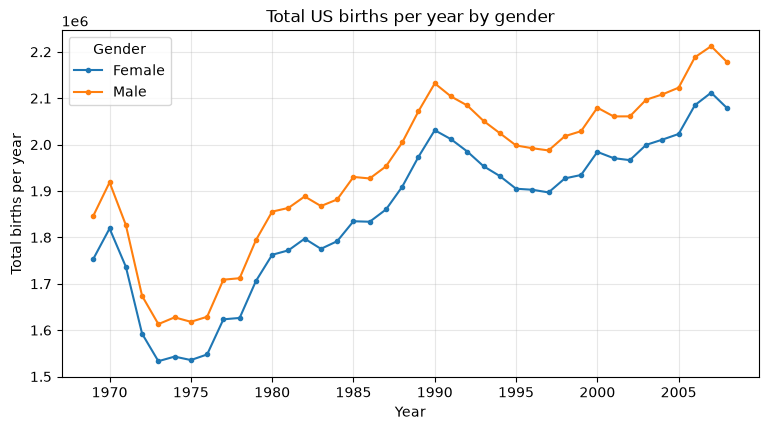

Average yearly gap (M - F): 92,568 births  (~5.0% of female births)


In [14]:
year_gender = births.pivot_table('births', index='year', columns='gender', aggfunc='sum')

ax = year_gender.plot(figsize=(9, 4.5), marker='o', markersize=3)
ax.set_xlabel('Year')
ax.set_ylabel('Total births per year')
ax.set_title('Total US births per year by gender')
ax.legend(title='Gender', labels=['Female', 'Male'])
plt.show()

gap = year_gender['M'] - year_gender['F']
print(f'Average yearly gap (M - F): {gap.mean():,.0f} births  '
      f'(~{(gap / year_gender["F"]).mean()*100:.1f}% of female births)')

In [15]:
# (a) Quartiles of the births column
quartiles = np.percentile(births['births'], [25, 50, 75])
q1, q2, q3 = quartiles
print('Q1, median, Q3 =', quartiles)

mu = q2                         # median as a robust "mean"
sig = 0.74 * (q3 - q1)          # robust standard deviation from the inter-quartile range
print(f'mu  (median)          = {mu:.1f}')
print(f'sig (0.74 * IQR)      = {sig:.1f}')

# For comparison: the ordinary (non-robust) statistics
print(f'\nOrdinary mean = {births["births"].mean():.1f},  ordinary std = {births["births"].std():.1f}')
print(f'Min = {births["births"].min()},  Max = {births["births"].max()}')

Q1, median, Q3 = [4358.  4814.  5289.5]
mu  (median)          = 4814.0
sig (0.74 * IQR)      = 689.3

Ordinary mean = 9762.3,  ordinary std = 28552.5
Min = 1,  Max = 199622


In [16]:
# (b) Keep only rows within 5 sigma of mu using query()
n_before = len(births)
births_clean = births.query('(births > @mu - 5 * @sig) & (births < @mu + 5 * @sig)')
print(f'Rows before: {n_before},  after: {len(births_clean)},  removed: {n_before - len(births_clean)}')
print(f'Accepted range: {mu - 5*sig:.0f} < births < {mu + 5*sig:.0f}')

# What kinds of rows were removed?
removed = births.drop(births_clean.index)
print('\nRemoved rows with day missing (NaN):', removed['day'].isna().sum())
print('Removed rows with day == 99         :', (removed['day'] == 99).sum())
print('Removed rows with another day value :', (~removed['day'].isna() & (removed['day'] != 99)).sum())
print('\nSample of removed rows:')
display(removed.sample(6, random_state=1))

Rows before: 15547,  after: 14610,  removed: 937
Accepted range: 1367 < births < 8261

Removed rows with day missing (NaN): 480
Removed rows with day == 99         : 350
Removed rows with another day value : 107

Sample of removed rows:


,year,month,day,gender,births,decade
10062,1982,3,99.0,M,4,1980
889,1970,2,29.0,M,44,1970
15336,2000,3,NaN,M,174808,2000
15215,1995,3,NaN,F,160096,1990
703,1969,11,99.0,M,56,1960
7571,1978,11,31.0,F,2,1970


In [17]:
# (c) Convert day to int. First show that it fails on the raw data...
try:
    births['day'].astype(int)
except Exception as e:
    print(type(e).__name__, ':', e)

# ...and that it works after cleaning
print('\nNaN left in cleaned day column:', births_clean['day'].isna().sum())
births_clean = births_clean.copy()
births_clean['day'] = births_clean['day'].astype(int)
print(births_clean.dtypes)

IntCastingNaNError : Cannot convert non-finite values (NA or inf) to integer.Replace or remove non-finite values or cast to an integer typethat supports these values (e.g. 'Int64')

NaN left in cleaned day column: 0
year      int64
month     int64
day       int64
gender      str
births    int64
decade    int64
dtype: object


In [18]:
# (a) Build a DatetimeIndex from year, month, day (yyyymmdd integer + explicit format)
births_clean.index = pd.to_datetime(
    10000 * births_clean['year'] + 100 * births_clean['month'] + births_clean['day'],
    format='%Y%m%d')

# Weekday: Monday=0 ... Sunday=6
births_clean['dayofweek'] = births_clean.index.dayofweek

print('Index type:', type(births_clean.index).__name__)
print('Date range:', births_clean.index.min().date(), 'to', births_clean.index.max().date())
display(births_clean.head())


Index type: DatetimeIndex
Date range: 1969-01-01 to 1988-12-31


,year,month,day,gender,births,decade,dayofweek
1969-01-01,1969,1,1,F,4046,1960,2
1969-01-01,1969,1,1,M,4440,1960,2
1969-01-02,1969,1,2,F,4454,1960,3
1969-01-02,1969,1,2,M,4548,1960,3
1969-01-03,1969,1,3,F,4548,1960,4


decade,1960,1970,1980
dayofweek,,,
0,5063.8,4689.1,5276.9
1,5286.1,4885.3,5503.8
2,5074.6,4750.4,5367.6
3,4978.3,4696.9,5333.5
4,5107.9,4782.1,5393.1
5,4651.1,4207.8,4483.9
6,4342.3,3979.3,4308.1


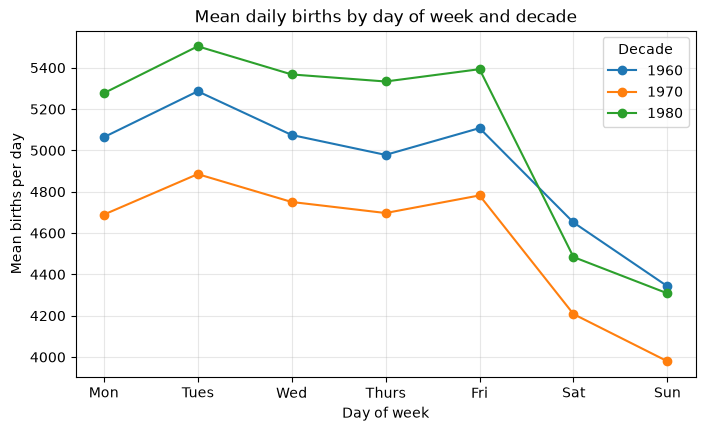

Weekend births relative to weekday births (%):
decade
1960   -11.9
1970   -14.0
1980   -18.2
dtype: float64


In [19]:
# (b) Mean births by weekday and decade
weekday_decade = births_clean.pivot_table('births', index='dayofweek', columns='decade', aggfunc='mean')
display(weekday_decade.round(1))

ax = weekday_decade.plot(figsize=(8, 4.5), marker='o')
ax.set_xticks(range(7))
ax.set_xticklabels(['Mon', 'Tues', 'Wed', 'Thurs', 'Fri', 'Sat', 'Sun'])
ax.set_xlabel('Day of week')
ax.set_ylabel('Mean births per day')
ax.set_title('Mean daily births by day of week and decade')
ax.legend(title='Decade')
plt.show()

# Weekend dip in numbers
wk = weekday_decade.loc[0:4].mean(); we = weekday_decade.loc[5:6].mean()
print('Weekend births relative to weekday births (%):')
print(((we / wk - 1) * 100).round(1))

In [20]:
# Mean births for each calendar date, grouped by (month, day) multi-index
births_by_date = births_clean.pivot_table('births', [births_clean.index.month, births_clean.index.day])
births_by_date.index.names = ['month', 'day']
print(births_by_date.shape)
display(births_by_date.head())

(366, 1)


births
month day          
1     1    4009.225
      2    4247.400
      3    4500.900
      4    4571.350
      5    4603.625

In [21]:
# (a) Turn the (month, day) multi-index into real dates using a dummy LEAP year (2012)
idx = births_by_date.index
births_by_date.index = pd.to_datetime(pd.DataFrame({
    'year': 2012,
    'month': idx.get_level_values('month'),
    'day': idx.get_level_values('day')}))

display(births_by_date.head())
print('Contains Feb 29?', pd.Timestamp('2012-02-29') in births_by_date.index)

,births
2012-01-01,4009.225
2012-01-02,4247.400
2012-01-03,4500.900
2012-01-04,4571.350
2012-01-05,4603.625


Contains Feb 29? True


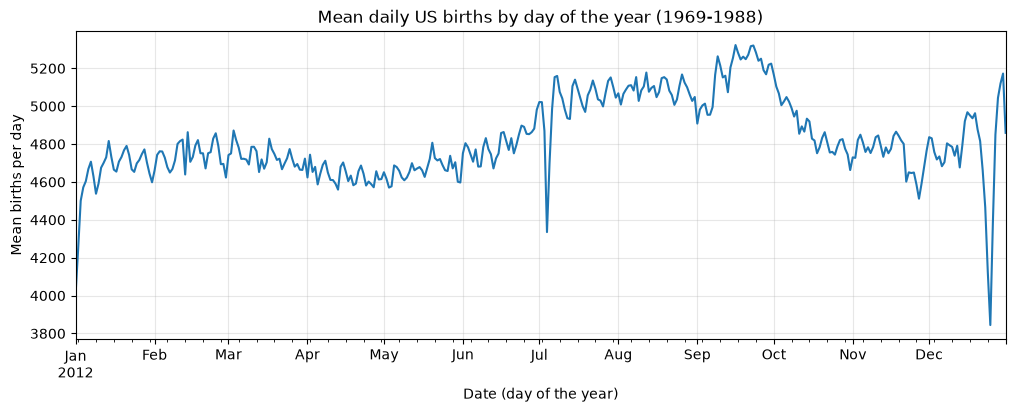

In [22]:
# (b) Plot mean births by date
fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, legend=False)
ax.set_xlabel('Date (day of the year)')
ax.set_ylabel('Mean births per day')
ax.set_title('Mean daily US births by day of the year (1969-1988)')
plt.show()

In [23]:
# Quantify the holiday dips: compare each holiday with the average of that calendar month
by = births_by_date['births']
fixed = {"New Year's Day (1 Jan)": '2012-01-01', 'Independence Day (4 Jul)': '2012-07-04',
         'Christmas Eve (24 Dec)': '2012-12-24', 'Christmas Day (25 Dec)': '2012-12-25'}
rows = []
for name, d in fixed.items():
    d = pd.Timestamp(d)
    month_mean = by[by.index.month == d.month].mean()
    rows.append((name, by[d], month_mean, (by[d] / month_mean - 1) * 100))
display(pd.DataFrame(rows, columns=['Holiday', 'Mean births', 'Month average', '% below month avg']).round(1))

,Holiday,Mean births,Month average,% below month avg
0,New Year's Day (1 Jan),4009.2,4644.5,-13.7
1,Independence Day (4 Jul),4335.3,5016.4,-13.6
2,Christmas Eve (24 Dec),4126.2,4761.6,-13.3
3,Christmas Day (25 Dec),3844.4,4761.6,-19.3


In [24]:
# (a) Same decade x gender table with groupby + unstack (uses the original `births` frame, as in Task 2)
gb_table = births.groupby(['decade', 'gender'])['births'].sum().unstack()
display(gb_table)

print('Identical to pivot table values? ', np.array_equal(gb_table.values, decade_gender.values))
print('Identical index/columns?         ', gb_table.index.equals(decade_gender.index) and
      list(gb_table.columns) == list(decade_gender.columns))
pd.testing.assert_frame_equal(gb_table, decade_gender, check_names=False)   # raises if they differ
print('assert_frame_equal passed (tables match)')

gender,F,M
decade,,
1960,1753634,1846572
1970,16263075,17121550
1980,18310351,19243452
1990,19479454,20420553
2000,18229309,19106428


Identical to pivot table values?  True
Identical index/columns?          True
assert_frame_equal passed (tables match)


In [27]:
# (b) Timing both approaches
t_pivot = %timeit -o births.pivot_table('births', index='decade', columns='gender', aggfunc='sum')
t_group = %timeit -o births.groupby(['decade', 'gender'])['births'].sum().unstack()


14.6 ms ± 569 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
5.72 ms ± 350 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [28]:
timing = pd.DataFrame({
    'Method': ["pivot_table('births', index='decade', columns='gender', aggfunc='sum')",
               "groupby(['decade','gender'])['births'].sum().unstack()"],
    'Mean time (ms)': [t_pivot.average * 1e3, t_group.average * 1e3],
    'Std dev (ms)': [t_pivot.stdev * 1e3, t_group.stdev * 1e3],
})
timing['Relative to groupby'] = timing['Mean time (ms)'] / timing['Mean time (ms)'].min()
display(timing.round(3))

,Method,Mean time (ms),Std dev (ms),Relative to groupby
0,"pivot_table('births', index='decade', columns=...",14.598,0.569,2.552
1,"groupby(['decade','gender'])['births'].sum().u...",5.721,0.350,1.000


In [29]:
# Five dates with the lowest mean births
lowest5 = by.nsmallest(5)
low = pd.DataFrame({'Date': lowest5.index.strftime('%d %b'), 'Mean births': lowest5.values.round(1)})
holiday_map = {'25 Dec': "Christmas Day", '01 Jan': "New Year's Day", '24 Dec': 'Christmas Eve',
               '02 Jan': "Day after New Year's (holiday-schedule / bridge day)", '04 Jul': 'Independence Day',
               '26 Dec': 'Day after Christmas (Boxing Day / holiday schedule)'}
low['Matching US holiday'] = low['Date'].map(holiday_map)
display(low)

,Date,Mean births,Matching US holiday
0,25 Dec,3844.4,Christmas Day
1,01 Jan,4009.2,New Year's Day
2,24 Dec,4126.2,Christmas Eve
3,02 Jan,4247.4,Day after New Year's (holiday-schedule / bridg...
4,04 Jul,4335.3,Independence Day


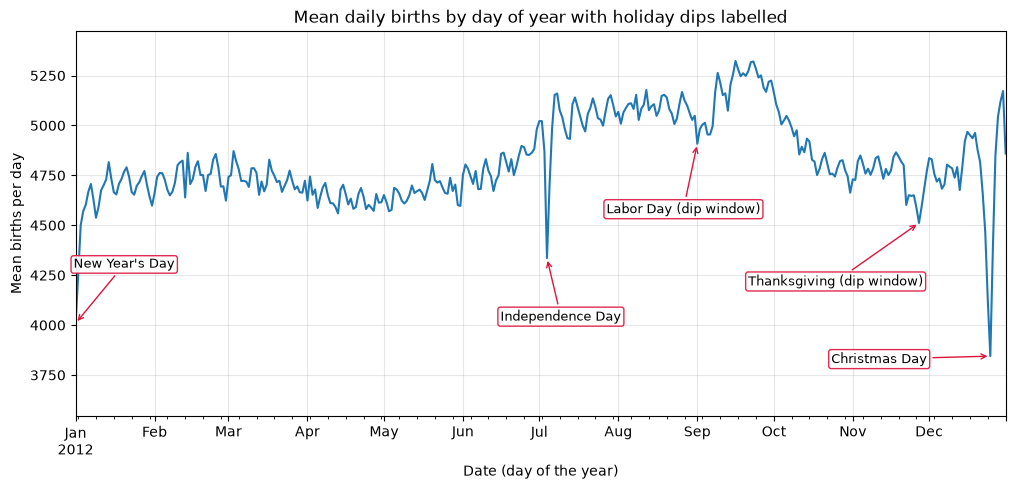

In [30]:
# Annotated plot. Labor Day and Thanksgiving move each year, so we mark the minimum inside their possible windows.
def window_min(start, end):
    seg = by[start:end]
    return seg.idxmin(), seg.min()

labor_d, labor_v   = window_min('2012-09-01', '2012-09-07')   # Labor Day (first Monday of Sep) falls on Sep 1-7
thanks_d, thanks_v = window_min('2012-11-22', '2012-11-28')   # 4th Thursday of Nov falls on Nov 22-28

marks = [("New Year's Day",  pd.Timestamp('2012-01-01'), by['2012-01-01'], (35, 40)),
         ('Independence Day', pd.Timestamp('2012-07-04'), by['2012-07-04'], (10, -45)),
         ('Labor Day (dip window)', labor_d, labor_v, (-10, -50)),
         ('Thanksgiving (dip window)', thanks_d, thanks_v, (-60, -45)),
         ('Christmas Day',  pd.Timestamp('2012-12-25'), by['2012-12-25'], (-80, -5))]

fig, ax = plt.subplots(figsize=(12, 5))
by.plot(ax=ax, legend=False)
for label, d, v, offset in marks:
    ax.annotate(label, xy=(d, v), xytext=offset, textcoords='offset points',
                ha='center', fontsize=9, arrowprops=dict(arrowstyle='->', color='crimson'),
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='crimson', alpha=0.9))
ax.set_xlabel('Date (day of the year)')
ax.set_ylabel('Mean births per day')
ax.set_title('Mean daily births by day of year with holiday dips labelled')
ax.set_ylim(by.min() - 300, by.max() + 150)
plt.show()
